# Ablation Runde 3: LGBM-Diagnose, Teacher-Labor & `init_score`

**Stand nach exp007:** XGB 0.96125 · CatBoost 0.96111 · **LGBM 0.95712** (in der Ablation mit schnellen Parametern aber 0.9608) · Blend 0.96129 · Public LB 0.96092.
Der Teacher liefert ca. 85 % des Gains, ist auf Train aber nur 0.955 gut. Hier wird getestet, was daraus noch herauszuholen ist.

| Teil | Frage |
|---|---|
| 1. LGBM-Diagnose | Warum ist LGBM im Hauptlauf so viel schlechter? Early Stopping auf Logloss **oder** die Parameter? |
| 2. Teacher-Labor | Welche Teacher (XGB flach/tief, LGBM, CatBoost, LogReg, MLP, Mix) sind auf den Train-Daten am besten? Schnelltest = AUC des Teacher-Logits gegen die Train-Labels (der Teacher sieht Train-Labels nie → kein Leak). |
| 3. Nutzung des Teachers | Als Feature, als Startwert (`init_score` / `base_margin`), mehrere Teacher, Teacher-Mix |
| 4. XGB-Kontrolle | Gilt das Ergebnis auch für XGB (dein bestes Modell)? |

**Projektdateien bleiben unangetastet.** `src/*.py` werden nur importiert, alles passiert im Speicher. Neue Dateien nur in `Results/ablation/` (Resume-fähig).
Setup wie Runde 2: Original-Zeilen **nicht** im Training, Statistiken gemeinsam, Teacher als Feature = Referenz `m0_ref` (muss ≈ 0.9608 ergeben).

In [1]:
import os, sys, time, json, warnings
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")

_p = Path.cwd().resolve()
for _cand in [_p, *_p.parents]:
    if (_cand / "src").is_dir():
        ROOT = _cand
        break
else:
    raise FileNotFoundError("Ordner 'src' nicht gefunden – Notebook im Projektordner starten.")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src import config as cfg
import src.data as data_mod
from src.data import load_data
print("Projektordner:", ROOT)

Projektordner: /home/cgd16/Desktop/Projekte/04 - Kaggle/Playground_Series_Season_6_Episode_10_Predicting_Airline_Satisfaction


In [3]:
import numpy as np
from src import config as cfg
from src.data import load_data
from src.cv import run_cv

cfg.SEEDS = [42]
cfg.N_SPLITS = 5
cfg.USE_ORIG_ROWS = False
cfg.ORIG_IN_STATS = True
cfg.VARIANT_SUFFIX = "_noOrigRows_dbg"   # eigener Ordner, überschreibt nichts
cfg.EXP_NAME = "dbg_lgbm_pipeline"

data = load_data(cfg.FEATURE_SET)
r = run_cv("lgbm", data, cfg.FEATURE_SET)
print("Pipeline-LGBM, 1 Seed, 5 Folds:", round(r["auc"], 6))

Originaldatensatz geladen: (129880, 22)
train (699635, 23) | test (299844, 22) | sample_submission (299844, 2)
Trainiere Original-Data Teacher Modell...
Teacher OOF-AUC auf Original: 0.994973
Original-Data Teacher Feature erfolgreich generiert!
Hinweis: Test hat keine fehlenden Arrival-Delay-Werte -> 'Arrival_Delay_Missing' entfernt
Feature-Set fs07: 91 Features (kategorisch: 9)
[lgbm] seed 42 fold 1: AUC=0.960850  best_iter=1844  time=68.17s
[lgbm] seed 42 fold 2: AUC=0.959978  best_iter=1921  time=77.58s
[lgbm] seed 42 fold 3: AUC=0.961679  best_iter=1875  time=69.71s
[lgbm] seed 42 fold 4: AUC=0.960987  best_iter=1410  time=52.69s
[lgbm] seed 42 fold 5: AUC=0.961014  best_iter=1680  time=62.13s
--> [lgbm] Seed 42 fertig | Single-Seed OOF-AUC: 0.960881
==> [lgbm] FINAL Seed-Averaged OOF-AUC: 0.960881 | Gesamtzeit: 332.05s

Pipeline-LGBM, 1 Seed, 5 Folds: 0.960881


In [ ]:
import numpy as np, pandas as pd
from src import config as cfg
from src.data import to_binary

FS, SUFFIX = "fs07", "_noOrigRows"
SEEDS = [42, 2026, 10, 23, 16, 2, 8, 46]
K = 10

y = to_binary(pd.read_csv(cfg.DATA_DIR / cfg.TRAIN_FILE)[cfg.TARGET]).reset_index(drop=True)

rows, averaged = [], {}
for model in ["lgbm", "xgb", "cat"]:
    d = cfg.MODELS_DIR / "saved_models" / f"{model}_{FS}{SUFFIX}"
    oofs = []
    for seed in SEEDS:
        oof = np.full(len(y), np.nan)
        for fold, (tr, va) in enumerate(StratifiedKFold(K, shuffle=True, random_state=seed).split(y, y), 1):
            f = d / f"pred_va_{model}_seed{seed}_fold{fold}.npy"
            if not f.exists():
                continue
            p = np.load(f)
            oof[va] = p
            rows.append(dict(model=model, seed=seed, fold=fold,
                             auc=roc_auc_score(y.iloc[va], p), p_mean=p.mean(), p_std=p.std()))
        oofs.append(oof)
    if all(~np.isnan(o).any() for o in oofs):
        averaged[model] = roc_auc_score(y, np.mean(oofs, axis=0))

df = pd.DataFrame(rows)
print("AUC je Modell und Seed (Mittel / Min / Max ueber die Folds):")
print(df.groupby(["model", "seed"])["auc"].agg(["mean", "min", "max"]).round(5))
print("\nSeed-gemittelte OOF-AUC:", {k: round(v, 6) for k, v in averaged.items()})
print("\nDie 12 schlechtesten Folds:")
print(df.sort_values("auc").head(12).round(5).to_string(index=False))

AUC je Modell und Seed (Mittel / Min / Max ueber die Folds):
               mean      min      max
model seed                           
cat   2     0.96094  0.95951  0.96258
      8     0.96096  0.95980  0.96244
      10    0.96099  0.95981  0.96238
      16    0.96094  0.95866  0.96181
      23    0.96097  0.95957  0.96193
      42    0.96094  0.95936  0.96175
      46    0.96097  0.95934  0.96363
      2026  0.96097  0.96055  0.96151
lgbm  2     0.96112  0.95981  0.96280
      8     0.96112  0.96005  0.96263
      10    0.96112  0.95999  0.96245
      16    0.95894  0.95654  0.96139
      23    0.95956  0.95813  0.96127
      42    0.96114  0.95960  0.96193
      46    0.96112  0.95953  0.96354
      2026  0.96115  0.96062  0.96172
xgb   2     0.96108  0.95984  0.96265
      8     0.96111  0.96001  0.96262
      10    0.96111  0.95989  0.96238
      16    0.96115  0.95902  0.96204
      23    0.96111  0.95986  0.96195
      42    0.96111  0.95951  0.96193
      46    0.96112  0.9594

In [5]:
from scipy.stats import rankdata

# 1) Welche LGBM-Seeds/Folds sind defekt?
d = df[df.model == "lgbm"].copy()
med = d["p_std"].median()
d["komprimiert"] = d["p_std"] < med - 0.03
print("p_std-Median LGBM:", round(med, 3))
print(d.groupby("seed")[["auc", "p_std"]].mean().round(4))
print("\nKomprimierte Folds:")
print(d[d.komprimiert].sort_values("p_std")[["seed", "fold", "auc", "p_std"]].round(4).to_string(index=False))

# 2) OOF/Test aus den Checkpoints neu zusammensetzen
def load_model(model, seeds):
    p = cfg.MODELS_DIR / "saved_models" / f"{model}_{FS}{SUFFIX}"
    oof = np.zeros((len(seeds), len(y))); te = 0
    for i, seed in enumerate(seeds):
        for fold, (tr, va) in enumerate(StratifiedKFold(K, shuffle=True, random_state=seed).split(y, y), 1):
            oof[i][va] = np.load(p / f"pred_va_{model}_seed{seed}_fold{fold}.npy")
            te += np.load(p / f"pred_te_{model}_seed{seed}_fold{fold}.npy") / (K * len(seeds))
    return oof.mean(0), te

seed_mean = d.groupby("seed")["auc"].mean()
GOOD = [s for s in SEEDS if seed_mean[s] > seed_mean.median() - 0.0005]
print("\nGute LGBM-Seeds:", GOOD)

o_lall, t_lall = load_model("lgbm", SEEDS)
o_lgood, t_lgood = load_model("lgbm", GOOD)
o_x, t_x = load_model("xgb", SEEDS)
o_c, t_c = load_model("cat", SEEDS)

print("\nOOF-AUC LGBM alle Seeds :", round(roc_auc_score(y, o_lall), 6))
print("OOF-AUC LGBM gute Seeds :", round(roc_auc_score(y, o_lgood), 6))
print("OOF-AUC XGB / CatBoost  :", round(roc_auc_score(y, o_x), 6), "/", round(roc_auc_score(y, o_c), 6))

combos = {"xgb+cat": [o_x, o_c],
          "xgb+cat+lgbm (alle Seeds)": [o_x, o_c, o_lall],
          "xgb+cat+lgbm (gute Seeds)": [o_x, o_c, o_lgood]}
for name, parts in combos.items():
    print(f"{name:28s} prob-Mittel {roc_auc_score(y, np.mean(parts, 0)):.6f} | "
          f"rank-Mittel {roc_auc_score(y, np.mean([rankdata(p) for p in parts], 0)):.6f}")

p_std-Median LGBM: 0.433
         auc   p_std
seed                
2     0.9611  0.4329
8     0.9611  0.4328
10    0.9611  0.4329
16    0.9589  0.2453
23    0.9596  0.3057
42    0.9611  0.4329
46    0.9611  0.4328
2026  0.9612  0.4328

Komprimierte Folds:
 seed  fold    auc  p_std
   23     2 0.9587 0.0235
   16     4 0.9581 0.0482
   23     4 0.9581 0.0484
   16     7 0.9581 0.0640
   16    10 0.9595 0.1005
   16     8 0.9579 0.1141
   16     5 0.9587 0.1829
   23     7 0.9594 0.2172
   23     5 0.9583 0.2182
   16     3 0.9597 0.3442
   16     6 0.9565 0.3499
   16     2 0.9596 0.3846

Gute LGBM-Seeds: [42, 2026, 10, 2, 8, 46]

OOF-AUC LGBM alle Seeds : 0.95712
OOF-AUC LGBM gute Seeds : 0.961239
OOF-AUC XGB / CatBoost  : 0.961248 / 0.96111
xgb+cat                      prob-Mittel 0.961281 | rank-Mittel 0.961282
xgb+cat+lgbm (alle Seeds)    prob-Mittel 0.960177 | rank-Mittel 0.960792
xgb+cat+lgbm (gute Seeds)    prob-Mittel 0.961293 | rank-Mittel 0.961295


In [ ]:
# nach der Ablationsstudie sind 16 und 23 defekt. 
# Diese werden in der Config-Datei auskommentiert  
# LGBM: Die Seeds 16 und 23 sind defekt, die sechs anderen (2, 8, 10, 42, 46, 2026) liegen sauber bei 0.9611. 
# In den schlechten Folds sind die Vorhersagen stark zusammengedrückt: 
# die Standardabweichung der Vorhersagen liegt bei 0.02–0.35 statt 0.433. Das spricht dafür, dass das Early Stopping dort viel zu früh abgebrochen hat, solange das Modell bei der kleinen Lernrate noch kaum Bäume hatte. Das ist meine Vermutung, ein Blick ins Log kann sie bestätigen. Suche dort die Fold-Zeilen mit AUC um 0.958 und schau, ob best_iter unter ca. 300 liegt (gesunde Folds haben 1400–1900).
# Zusammenführen der Seeds: 
# Die Mittelung der defekten Seeds mit den guten zieht die Seed-gemittelte LGBM-OOF auf 0.95712 und damit den Blend nach unten

In [ ]:
# tbd:
# Nichts neu rechnen. Wenn du LGBM in einem Blend verwendest, dann nur mit den sechs guten Seeds. Sonst lass ihn einfach weg.
# Falls du LGBM später doch neu trainierst, setze in models.py metric="auc" in den LGBM-Konstruktor und in der Config die Lernrate auf 0.02 und die Geduld (EARLY_STOPPING) auf 300. Ob das alleine das Problem behebt, habe ich nicht getestet. In der Ablation (L2) lag diese Lernrate gleichauf mit den Hauptparametern.
# Der nächste Hebel ist Modellvielfalt statt noch mehr vom Gleichen. Du hast Vorhersagen aus mehreren Experimenten (andere Feature-Sets, mit und ohne Original-Zeilen), die sich in ihren Fehlern unterscheiden. Sie liegen schon als Dateien vor und lassen sich ohne Training blenden. Danach käme ein MLP als wirklich andere Modellfamilie.

## Einstellungen

In [ ]:
FEATURE_SET = "fs06"           # gleiche Funktionsliste wie fs07
ABL_SEED = 42
NOISE_SEEDS = [42, 2026, 10]
ABL_SPLITS = 5
NOISE_PRIOR = 2e-5             # Fallback, falls nur ein Seed
MIN_EFFECT = 2e-5

FAST_LGBM = dict(learning_rate=0.05, n_estimators=3000)    # wie Runde 2 -> m0_ref ~ r0_ref (0.9608)
FAST_ES = 100
FAST_XGB = dict(learning_rate=0.05, n_estimators=3000, max_depth=7)

TEACHER_SPLITS = 5
TOP_K = 3

RUN_SLOW = True        # Diagnose-Laeufe mit Lernrate 0.007 (dauern laenger)
RUN_CAT_TEACHER = True
RUN_MLP_TEACHER = True
XGB_CHECK = True

RESUME = True
OUT_DIR = cfg.RESULTS_DIR / "ablation"
(OUT_DIR / "teachers").mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT_DIR / "round3_results.csv"
print("Hauptparameter LGBM (config):", cfg.PARAMS["lgbm"])

Hauptparameter LGBM (config): {'learning_rate': 0.007, 'num_leaves': 128, 'max_depth': 10, 'min_child_samples': 100, 'subsample': 0.85, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'device': 'cuda'}


## Hilfsfunktionen: Daten & Teacher-Register

In [ ]:
_DATA = {}

@contextmanager
def _patched(orig_in_stats):
    old_fn = data_mod.add_features_joint
    def wrapper(train, test, orig, feature_set, orig_in_stats=True):
        return old_fn(train, test, orig, feature_set, orig_in_stats=_patched.ois)
    _patched.ois = orig_in_stats
    try:
        data_mod.add_features_joint = wrapper
        yield
    finally:
        data_mod.add_features_joint = old_fn

def get_data():
    if "base" not in _DATA:
        print("[Daten] lade ...")
        with _patched(True):
            _DATA["base"] = load_data(FEATURE_SET)
    return _DATA["base"]

def _logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))

TEACHERS = {}   # Name -> dict(train, test, orig, auc_train, auc_orig)

def _register(name, train, test, orig):
    d = get_data()
    TEACHERS[name] = dict(train=np.asarray(train), test=np.asarray(test), orig=np.asarray(orig),
                          auc_train=roc_auc_score(d.y, train), auc_orig=roc_auc_score(d.y_orig, orig))
    return TEACHERS[name]

def register_builtin():
    d = get_data()
    return _register("T0_xgb_d8", d.X["original_teacher_logit"].values,
                     d.X_test["original_teacher_logit"].values, d.X_orig["original_teacher_logit"].values)

## CV-Funktion (LGBM oder XGB)
Wie in Runde 2 (gleiche Folds, In-Fold-Target-Encoding auf `Route_ID`, keine Original-Zeilen). Neu:
- Teacher als Feature (`feat`, mehrere möglich) **und/oder** als Startwert (`init`, Mittel der Logits mehrerer Teacher).
- `metric="auc"`: nur AUC beobachten. `metric="both"`: wie `models.py` (Logloss **und** AUC → Early Stopping greift beim früheren der beiden).

In [ ]:
def te_map(k_train, y_train, k_valid, smooth=20.0):
    prior = y_train.mean()
    stats = pd.DataFrame({"k": k_train, "y": y_train}).groupby("k")["y"].agg(["sum", "count"])
    mapping = (stats["sum"] + prior * smooth) / (stats["count"] + smooth)
    return pd.Series(k_valid).map(mapping).fillna(prior).values.astype(np.float32)

DEFAULT_SPEC = dict(model="lgbm", feat=["T0_xgb_d8"], init=None, lgbm=FAST_LGBM, xgb=FAST_XGB,
                    es=FAST_ES, metric="auc", te=True, parent="m0_ref", desc="")

def _fit_predict(spec, X_tr, y_tr, X_va, y_va, i_tr, i_va, seed):
    if spec["model"] == "lgbm":
        params = {**cfg.PARAMS["lgbm"], **spec["lgbm"]}
        mkw = dict(metric="auc") if spec["metric"] == "auc" else {}
        m = lgb.LGBMClassifier(**params, **mkw, random_state=seed, verbosity=-1, n_jobs=-1)
        fk = dict(eval_set=[(X_va, y_va)], eval_metric="auc",
                  callbacks=[lgb.early_stopping(spec["es"], verbose=False)])
        if i_tr is not None:
            fk.update(init_score=i_tr, eval_init_score=[i_va])
        m.fit(X_tr, y_tr, **fk)
        p = (m.predict(X_va, raw_score=True) + i_va) if i_tr is not None else m.predict_proba(X_va)[:, 1]
        g = pd.Series(m.booster_.feature_importance("gain"), index=m.booster_.feature_name())
        return p, m.best_iteration_, g
    # XGB
    params = {**cfg.PARAMS["xgb"], **spec["xgb"]}
    m = xgb.XGBClassifier(**params, objective="binary:logistic", eval_metric="auc", enable_categorical=True,
                          early_stopping_rounds=spec["es"], random_state=seed, n_jobs=-1)
    fk = dict(eval_set=[(X_va, y_va)], verbose=False)
    if i_tr is not None:
        fk.update(base_margin=i_tr, base_margin_eval_set=[i_va])
    m.fit(X_tr, y_tr, **fk)
    p = m.predict(X_va, output_margin=True, base_margin=i_va) if i_tr is not None else m.predict_proba(X_va)[:, 1]
    g = pd.Series(m.get_booster().get_score(importance_type="gain"))
    return p, m.best_iteration, g

def run_cv(spec, seed=ABL_SEED, n_splits=ABL_SPLITS):
    d = get_data()
    X, y = d.X.drop(columns=["original_teacher_logit"]).copy(), d.y
    for t in spec["feat"]:
        X["T_" + t] = TEACHERS[t]["train"]
    init = None
    if spec["init"]:
        init = np.mean([TEACHERS[t]["train"] for t in spec["init"]], axis=0)
    has_te = spec["te"] and "Route_ID" in X.columns

    oof = np.zeros(len(X)); fold_aucs, best_its = [], []
    imp = pd.Series(0.0, index=list(X.columns) + (["Route_Target_Enc"] if has_te else []))
    for tr, va in StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(X, y):
        X_tr, y_tr = X.iloc[tr].copy(), y.iloc[tr]
        X_va, y_va = X.iloc[va].copy(), y.iloc[va]
        if has_te:
            inner = np.zeros(len(X_tr), dtype=np.float32)
            for a, b in StratifiedKFold(5, shuffle=True, random_state=seed).split(X_tr, y_tr):
                inner[b] = te_map(X_tr["Route_ID"].iloc[a], y_tr.iloc[a], X_tr["Route_ID"].iloc[b])
            X_tr["Route_Target_Enc"] = inner
            X_va["Route_Target_Enc"] = te_map(X_tr["Route_ID"], y_tr, X_va["Route_ID"])
        i_tr = init[tr] if init is not None else None
        i_va = init[va] if init is not None else None
        p, bi, g = _fit_predict(spec, X_tr, y_tr, X_va, y_va, i_tr, i_va, seed)
        oof[va] = p
        fold_aucs.append(roc_auc_score(y_va, p)); best_its.append(bi)
        imp = imp.add(g, fill_value=0.0)
    return dict(auc=roc_auc_score(y, oof), fold_aucs=fold_aucs, n_features=X_tr.shape[1],
                mean_best_iter=float(np.mean(best_its)), importance=imp / imp.sum())

## Ergebnisverwaltung (Resume über CSV)

In [ ]:
SPECS, results = {}, {}

def save_results():
    pd.DataFrame([dict(variant=n, seed=s, auc=r["auc"], fold_aucs=json.dumps(r["fold_aucs"]),
                       n_features=r["n_features"], mean_best_iter=r["mean_best_iter"], time=r.get("time", np.nan),
                       desc=r.get("desc", ""), parent=r.get("parent", "m0_ref"))
                  for (n, s), r in results.items()]).to_csv(RESULTS_CSV, index=False)

def load_results():
    if RESUME and RESULTS_CSV.exists():
        for _, row in pd.read_csv(RESULTS_CSV).iterrows():
            results[(row["variant"], int(row["seed"]))] = dict(
                auc=row["auc"], fold_aucs=json.loads(row["fold_aucs"]), n_features=int(row["n_features"]),
                mean_best_iter=row["mean_best_iter"], time=row["time"], desc=row["desc"],
                parent=row["parent"], importance=None)
        print(f"{len(results)} Ergebnisse aus {RESULTS_CSV.name} geladen.")

def run_variant(name, spec=None, seed=ABL_SEED):
    spec = {**DEFAULT_SPEC, **(spec or {})}
    SPECS[name] = spec
    if (name, seed) in results:
        r = results[(name, seed)]
        print(f"{name:34s} seed={seed:<5d} AUC={r['auc']:.6f}  best_it~{r['mean_best_iter']:.0f}  (aus CSV)")
        return r
    t0 = time.time()
    r = run_cv(spec, seed)
    r.update(time=time.time() - t0, desc=spec["desc"], parent=spec["parent"])
    results[(name, seed)] = r
    save_results()
    print(f"{name:34s} seed={seed:<5d} AUC={r['auc']:.6f}  Features={r['n_features']:3d}  "
          f"best_it~{r['mean_best_iter']:.0f}  {r['time']:.0f}s")
    return r

load_results()

## Referenz & Rauschgrenze
`m0_ref` = Teacher `T0` (dein bisheriger XGB-Teacher) als Feature, keine Original-Zeilen, schnelle LGBM-Parameter. Muss ≈ **0.9608** ergeben (wie `r0_ref` in Runde 2).

In [ ]:
register_builtin()
print(f"T0_xgb_d8: AUC Train {TEACHERS['T0_xgb_d8']['auc_train']:.4f} | AUC Original (OOF) {TEACHERS['T0_xgb_d8']['auc_orig']:.4f}")

for s in NOISE_SEEDS:
    run_variant("m0_ref", dict(parent="m0_ref", desc="Referenz: T0 als Feature, LGBM schnell"), seed=s)

aucs = [results[("m0_ref", s)]["auc"] for s in NOISE_SEEDS]
NOISE = float(np.std(aucs, ddof=1)) if len(aucs) > 1 else NOISE_PRIOR
THR = max(2 * NOISE, MIN_EFFECT)
print(f"\nm0_ref AUCs: {[round(a, 6) for a in aucs]} | Rauschen {NOISE:.6f} | Schwelle {THR:.6f}")

[Daten] lade ...
Originaldatensatz geladen: (129880, 22)
train (699635, 23) | test (299844, 22) | sample_submission (299844, 2)
Trainiere Original-Data Teacher Modell...
Teacher OOF-AUC auf Original: 0.994973
Original-Data Teacher Feature erfolgreich generiert!
Hinweis: Test hat keine fehlenden Arrival-Delay-Werte -> 'Arrival_Delay_Missing' entfernt
Feature-Set fs06: 91 Features (kategorisch: 9)
T0_xgb_d8: AUC Train 0.9550 | AUC Original (OOF) 0.9950
m0_ref                             seed=42    AUC=0.959935  Features= 92  best_it~186  50s
m0_ref                             seed=2026  AUC=0.960751  Features= 92  best_it~193  52s
m0_ref                             seed=10    AUC=0.960727  Features= 92  best_it~208  54s

m0_ref AUCs: [0.959935, 0.960751, 0.960727] | Rauschen 0.000464 | Schwelle 0.000928


## Teil 1: LGBM-Diagnose
Der Hauptlauf (`models.py`) nutzt Lernrate 0.007, `num_leaves=128`, `max_depth=10`, Early Stopping 200 und überwacht **Logloss und AUC** (stoppt beim früheren der beiden).

| Variante | Zweck |
|---|---|
| `L0_main_as_is` | Hauptparameter, Logloss+AUC wie `models.py` → sollte ≈ 0.957 reproduzieren |
| `L1_main_auc_only` | identisch, aber **nur AUC** beobachten → Early-Stopping-Effekt isoliert |
| `L2_lr0.02` | größere Lernrate, nur AUC |
| `L3_simple_trees` | einfachere Bäume (31 Blätter) |
| `L4_shallow` | sehr flache Bäume (15 Blätter, Tiefe 6) |

**Lesehilfe:** `L1` ≫ `L0` → Early-Stopping-Metrik ist die Ursache (Fix: eine Zeile in `models.py`). `L1` ≈ `L0` → die Parameter sind das Problem (dann zählen `L2`–`L4`).

In [ ]:
DIAG = {
    "L2_lr0.02":        dict(lgbm=dict(learning_rate=0.02, n_estimators=5000), es=100),
    "L3_simple_trees":  dict(lgbm=dict(learning_rate=0.03, n_estimators=5000, num_leaves=31, max_depth=-1,
                                       min_child_samples=200, colsample_bytree=0.5), es=100),
    "L4_shallow":       dict(lgbm=dict(learning_rate=0.03, n_estimators=5000, num_leaves=15, max_depth=6,
                                       min_child_samples=300, colsample_bytree=0.5, reg_lambda=5.0), es=100),
}
SLOW = {
    "L0_main_as_is":    dict(lgbm=dict(n_estimators=10000), es=200, metric="both"),
    "L1_main_auc_only": dict(lgbm=dict(n_estimators=10000), es=200, metric="auc"),
}
todo = {**(SLOW if RUN_SLOW else {}), **DIAG}
for name, sp in todo.items():
    run_variant(name, {**sp, "desc": name})

L0_main_as_is                      seed=42    AUC=0.960973  Features= 92  best_it~1880  369s
L1_main_auc_only                   seed=42    AUC=0.960995  Features= 92  best_it~1787  345s
L2_lr0.02                          seed=42    AUC=0.960895  Features= 92  best_it~525  104s
L3_simple_trees                    seed=42    AUC=0.960885  Features= 92  best_it~911  84s
L4_shallow                         seed=42    AUC=0.960871  Features= 92  best_it~1557  61s


## Teil 2: Teacher-Labor
Jeder Teacher wird wie in `data.py` auf dem **Original** trainiert (5-Fold: Original-Zeilen bekommen ihren OOF-Wert, Train/Test das Mittel der Fold-Modelle). Bewertet wird die **AUC des Logits gegen die Train-Labels**: je höher, desto besser überträgt sich das Wissen aus dem Original auf die Wettbewerbsdaten.

In [ ]:
def teacher_cols(d):
    return [c for c in d.X.columns
            if c not in ("original_teacher_logit", "Route_ID", "Route_Target_Enc") and c in d.X_orig.columns]

_LIN = {}
def get_linear_mats(feats):
    """One-Hot + Standardisierung fuer LogReg/MLP (label-frei auf Train+Test+Original gefittet)."""
    if "m" in _LIN:
        return _LIN["m"]
    from sklearn.preprocessing import StandardScaler
    from sklearn.impute import SimpleImputer
    d = get_data()
    full = pd.concat([d.X[feats], d.X_test[feats], d.X_orig[feats]], ignore_index=True)
    cats = [c for c in d.cat_cols if c in feats]
    num = [c for c in feats if c not in cats]
    N = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(full[num].astype(float)))
    C = pd.get_dummies(full[cats].astype(str), dtype=np.float32).values
    M = np.hstack([N.astype(np.float32), C]).astype(np.float32)
    n1, n2 = len(d.X), len(d.X_test)
    _LIN["m"] = (M[:n1], M[n1:n1 + n2], M[n1 + n2:])
    return _LIN["m"]

def _fit_family(family, params, Xa, ya, Xs, cats):
    if family == "xgb":
        m = xgb.XGBClassifier(**params, tree_method="hist", enable_categorical=True,
                              device="cuda" if cfg.USE_GPU else "cpu", random_state=42, n_jobs=-1)
    elif family == "lgbm":
        m = lgb.LGBMClassifier(**params, random_state=42, verbosity=-1, n_jobs=-1)
    elif family == "cat":
        from catboost import CatBoostClassifier
        as_str = {c: str for c in cats}
        Xa, Xs = Xa.astype(as_str), [x.astype(as_str) for x in Xs]
        m = CatBoostClassifier(**params, loss_function="Logloss", random_seed=42, cat_features=cats, verbose=False,
                               task_type="GPU" if cfg.USE_GPU else "CPU")
    elif family == "lr":
        from sklearn.linear_model import LogisticRegression
        m = LogisticRegression(**params, max_iter=500)
    elif family == "mlp":
        from sklearn.neural_network import MLPClassifier
        m = MLPClassifier(**params, random_state=42)
    m.fit(Xa, ya)
    return [m.predict_proba(x)[:, 1] for x in Xs]

def build_teacher(name, family, params):
    f = OUT_DIR / "teachers" / f"{name}.npz"
    if RESUME and f.exists():
        z = np.load(f)
        r = _register(name, z["train"], z["test"], z["orig"])
        print(f"{name:14s} (aus Datei)   AUC Train {r['auc_train']:.4f} | Orig-OOF {r['auc_orig']:.4f}")
        return r
    t0 = time.time()
    d = get_data(); feats = teacher_cols(d); cats = [c for c in d.cat_cols if c in feats]
    if family in ("lr", "mlp"):
        Mtr, Mte, Mor = get_linear_mats(feats)
        A, T, Tt = Mor, Mtr, Mte
        sl = lambda M, idx: M[idx]
    else:
        A, T, Tt = d.X_orig[feats], d.X[feats], d.X_test[feats]
        sl = lambda M, idx: M.iloc[idx]
    oof = np.zeros(len(d.X_orig)); p_tr = np.zeros(len(d.X)); p_te = np.zeros(len(d.X_test))
    for a, b in StratifiedKFold(TEACHER_SPLITS, shuffle=True, random_state=42).split(d.X_orig, d.y_orig):
        pb, ptr, pte = _fit_family(family, params, sl(A, a), d.y_orig.iloc[a], [sl(A, b), T, Tt], cats)
        oof[b] = pb; p_tr += ptr / TEACHER_SPLITS; p_te += pte / TEACHER_SPLITS
    tr, te, orr = _logit(p_tr), _logit(p_te), _logit(oof)
    np.savez(f, train=tr, test=te, orig=orr)
    r = _register(name, tr, te, orr)
    print(f"{name:14s} AUC Train {r['auc_train']:.4f} | Orig-OOF {r['auc_orig']:.4f} | {time.time() - t0:.0f}s")
    return r

TEACHER_DEFS = {
    "xgb_d4":     ("xgb", dict(n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8,
                               colsample_bytree=0.5, min_child_weight=5)),
    "xgb_d6_reg": ("xgb", dict(n_estimators=800, learning_rate=0.04, max_depth=6, subsample=0.7,
                               colsample_bytree=0.5, min_child_weight=10, reg_lambda=5.0)),
    "lgbm_31":    ("lgbm", dict(n_estimators=1000, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                                subsample=0.8, subsample_freq=1, colsample_bytree=0.5)),
    "logreg":     ("lr", dict(C=0.5)),
}
if RUN_CAT_TEACHER:
    TEACHER_DEFS["cat_d6"] = ("cat", dict(iterations=1500, learning_rate=0.05, depth=6))
if RUN_MLP_TEACHER:
    TEACHER_DEFS["mlp"] = ("mlp", dict(hidden_layer_sizes=(128, 64), early_stopping=True, n_iter_no_change=5,
                                       max_iter=60, batch_size=512))

for name, (fam, prm) in TEACHER_DEFS.items():
    try:
        build_teacher(name, fam, prm)
    except Exception as e:
        print(f"{name}: uebersprungen ({type(e).__name__}: {str(e)[:120]})")

xgb_d4         AUC Train 0.9548 | Orig-OOF 0.9947 | 9s
xgb_d6_reg     AUC Train 0.9550 | Orig-OOF 0.9948 | 11s
lgbm_31        AUC Train 0.9549 | Orig-OOF 0.9951 | 30s
logreg         AUC Train 0.9458 | Orig-OOF 0.9773 | 17s
cat_d6         AUC Train 0.9550 | Orig-OOF 0.9949 | 71s
mlp            AUC Train 0.9532 | Orig-OOF 0.9931 | 23s


,auc_train,auc_orig_oof,gap
ens_top3,0.9551,0.9951,0.0399
cat_d6,0.9550,0.9949,0.0398
xgb_d6_reg,0.9550,0.9948,0.0398
T0_xgb_d8,0.9550,0.9950,0.0400
ens_all,0.9549,0.9948,0.0398
lgbm_31,0.9549,0.9951,0.0402
xgb_d4,0.9548,0.9947,0.0399
mlp,0.9532,0.9931,0.0399
logreg,0.9458,0.9773,0.0315


Bester Einzel-Teacher: cat_d6 | Top-3: ['cat_d6', 'xgb_d6_reg', 'T0_xgb_d8']
Mix Top-3: AUC Train 0.9551  |  alle: 0.9549


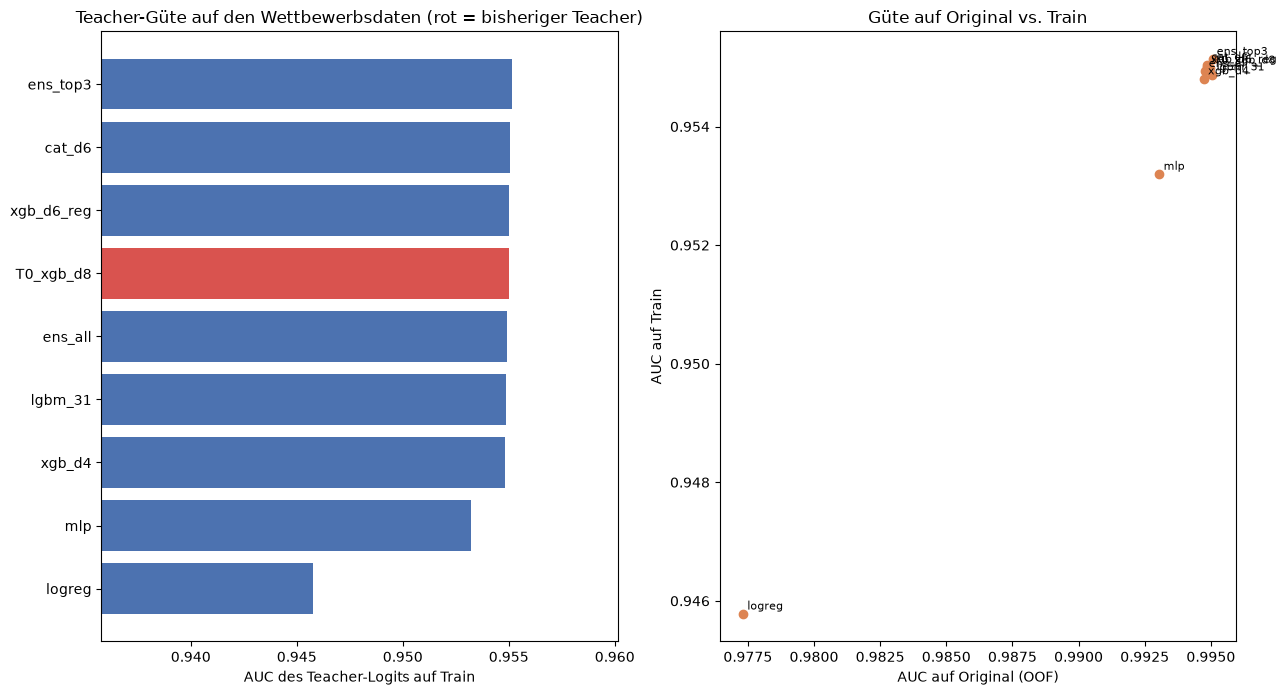

In [ ]:
# Mischungen: Mittel der Logits der besten Teacher (nach Train-AUC)
singles = {k: v for k, v in TEACHERS.items() if not k.startswith("ens_")}
rank = sorted(singles, key=lambda k: singles[k]["auc_train"], reverse=True)
top = rank[:TOP_K]

def _mix(names):
    return (np.mean([TEACHERS[n]["train"] for n in names], axis=0),
            np.mean([TEACHERS[n]["test"] for n in names], axis=0),
            np.mean([TEACHERS[n]["orig"] for n in names], axis=0))

ENS_TOP = f"ens_top{TOP_K}"
_register(ENS_TOP, *_mix(top))
_register("ens_all", *_mix(rank))
BEST = rank[0]

lab = pd.DataFrame({k: dict(auc_train=v["auc_train"], auc_orig_oof=v["auc_orig"],
                            gap=v["auc_orig"] - v["auc_train"]) for k, v in TEACHERS.items()}).T
lab = lab.sort_values("auc_train", ascending=False)
display(lab.round(4))
print(f"Bester Einzel-Teacher: {BEST} | Top-{TOP_K}: {top}")
print(f"Mix Top-{TOP_K}: AUC Train {TEACHERS[ENS_TOP]['auc_train']:.4f}  |  alle: {TEACHERS['ens_all']['auc_train']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * len(lab) + 3))
l = lab.iloc[::-1]
axes[0].barh(l.index, l["auc_train"], color=["#d9534f" if i == "T0_xgb_d8" else "#4c72b0" for i in l.index])
axes[0].set_xlim(max(0.9, l["auc_train"].min() - 0.01), l["auc_train"].max() + 0.005)
axes[0].set_xlabel("AUC des Teacher-Logits auf Train"); axes[0].set_title("Teacher-Güte auf den Wettbewerbsdaten (rot = bisheriger Teacher)")
axes[1].scatter(lab["auc_orig_oof"], lab["auc_train"], color="#dd8452")
for k, rw in lab.iterrows():
    axes[1].annotate(k, (rw["auc_orig_oof"], rw["auc_train"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1].set_xlabel("AUC auf Original (OOF)"); axes[1].set_ylabel("AUC auf Train")
axes[1].set_title("Güte auf Original vs. Train")
plt.tight_layout(); plt.show()

## Teil 3: Wie nutzt man den Teacher am besten? (LGBM)
| Variante | Teacher-Nutzung |
|---|---|
| `m1_init_T0` | `T0` als **Startwert** (`init_score`), nicht als Feature |
| `m2_init_T0_plus_feat` | `T0` als Startwert **und** als Feature |
| `m3_feat_best` | bester Einzel-Teacher als Feature |
| `m4_feat_top3` | die Top-3-Teacher als getrennte Features |
| `m5_init_mix` | Mix der Top-3 als Startwert |
| `m6_init_mix_plus_feats` | Mix als Startwert + Top-3 als Features |
| `m7_feat_mix` | Mix als ein einziges Feature |

In [ ]:
run_variant("m1_init_T0",             dict(feat=[], init=["T0_xgb_d8"], desc="T0 als init_score"))
run_variant("m2_init_T0_plus_feat",   dict(feat=["T0_xgb_d8"], init=["T0_xgb_d8"], desc="T0 init_score + Feature"))
run_variant("m3_feat_best",           dict(feat=[BEST], desc=f"bester Teacher ({BEST}) als Feature"))
run_variant("m4_feat_top3",           dict(feat=top, desc=f"Top-{TOP_K} als Features"))
run_variant("m5_init_mix",            dict(feat=[], init=top, desc=f"Mix Top-{TOP_K} als init_score"))
run_variant("m6_init_mix_plus_feats", dict(feat=top, init=top, desc="Mix init_score + Top-Teacher als Features"))
run_variant("m7_feat_mix",            dict(feat=[ENS_TOP], desc=f"Mix Top-{TOP_K} als ein Feature"))

m1_init_T0                         seed=42    AUC=0.951780  Features= 91  best_it~223  56s
m2_init_T0_plus_feat               seed=42    AUC=0.945983  Features= 92  best_it~116  37s
m3_feat_best                       seed=42    AUC=0.960671  Features= 92  best_it~204  52s
m4_feat_top3                       seed=42    AUC=0.960720  Features= 94  best_it~174  48s
m5_init_mix                        seed=42    AUC=0.956793  Features= 91  best_it~373  79s
m6_init_mix_plus_feats             seed=42    AUC=0.952279  Features= 94  best_it~123  42s
m7_feat_mix                        seed=42    AUC=0.960755  Features= 92  best_it~186  54s


{'auc': 0.9607545835953069,
 'fold_aucs': [0.9608978730304998,
  0.9598097153550333,
  0.9614477932950352,
  0.960810795754697,
  0.9608557684692113],
 'n_features': 92,
 'mean_best_iter': 186.0,
 'importance': Age                                  0.002167
 Flight_Distance                      0.000755
 Inflight_wifi_service                0.001397
 Departure/Arrival_time_convenient    0.000238
 Ease_of_Online_booking               0.000953
                                        ...   
 Group_Dist_Std                       0.000055
 Diff_From_Group_Dist_Mean            0.001304
 Class_DepDelay_Mean                  0.000018
 T_ens_top3                           0.853775
 Route_Target_Enc                     0.004256
 Length: 92, dtype: float64,
 'time': 53.967315435409546,
 'desc': 'Mix Top-3 als ein Feature',
 'parent': 'm0_ref'}

## Teil 4: XGB-Kontrolle
XGB ist dein bestes Modell. Hier wird die wichtigste Frage (Teacher als Feature vs. `base_margin`) mit XGB wiederholt. Eigene Referenz `x0_ref`.

In [ ]:
if XGB_CHECK:
    X0 = dict(model="xgb", parent="x0_ref")
    run_variant("x0_ref",          {**X0, "desc": "XGB: T0 als Feature (Referenz)"})
    run_variant("x1_init_T0",      {**X0, "feat": [], "init": ["T0_xgb_d8"], "desc": "XGB: T0 als base_margin"})
    run_variant("x2_feat_best",    {**X0, "feat": [BEST], "desc": f"XGB: {BEST} als Feature"})
    run_variant("x3_init_mix",     {**X0, "feat": [], "init": top, "desc": "XGB: Mix als base_margin"})
else:
    print("XGB_CHECK = False -> uebersprungen")

x0_ref                             seed=42    AUC=0.960866  Features= 92  best_it~332  12s
x1_init_T0                         seed=42    AUC=0.959193  Features= 91  best_it~1104  27s
x2_feat_best                       seed=42    AUC=0.960836  Features= 92  best_it~364  13s
x3_init_mix                        seed=42    AUC=0.959812  Features= 91  best_it~572  17s


## Ergebnisse

In [ ]:
def build_table():
    rows = []
    for (name, seed), r in results.items():
        if seed != ABL_SEED:
            continue
        par = results.get((r["parent"], ABL_SEED))
        if par is None or name == r["parent"]:
            delta, better, code_ = np.nan, np.nan, "referenz"
        else:
            delta = r["auc"] - par["auc"]
            better = int((np.array(r["fold_aucs"]) > np.array(par["fold_aucs"])).sum())
            code_ = "besser" if delta > THR else ("schlechter" if delta < -THR else "neutral")
        rows.append(dict(variant=name, parent=r["parent"], auc=r["auc"], delta_vs_parent=delta,
                         better_folds=better, best_iter=r["mean_best_iter"], n_features=r["n_features"],
                         urteil=code_, desc=r["desc"]))
    return pd.DataFrame(rows).set_index("variant")

table = build_table()
try:
    display(table.style.format({"auc": "{:.6f}", "delta_vs_parent": "{:+.6f}", "best_iter": "{:.0f}"})
            .background_gradient(subset=["delta_vs_parent"], cmap="RdYlGn"))
except Exception:
    display(table.round(6))
print(f"Schwelle fuer echten Effekt: +/- {THR:.6f} | Delta je Variante gegenueber ihrer Referenz (parent)")

,parent,auc,delta_vs_parent,better_folds,best_iter,n_features,urteil,desc
variant,,,,,,,,
m0_ref,m0_ref,0.959935,NaN,NaN,186.2,92,referenz,"Referenz: T0 als Feature, LGBM schnell"
L0_main_as_is,m0_ref,0.960973,0.001038,5.0,1879.8,92,besser,L0_main_as_is
L1_main_auc_only,m0_ref,0.960995,0.001060,5.0,1786.8,92,besser,L1_main_auc_only
L2_lr0.02,m0_ref,0.960895,0.000960,4.0,525.2,92,besser,L2_lr0.02
L3_simple_trees,m0_ref,0.960885,0.000950,5.0,911.0,92,besser,L3_simple_trees
L4_shallow,m0_ref,0.960871,0.000936,5.0,1557.2,92,besser,L4_shallow
m1_init_T0,m0_ref,0.951780,-0.008155,0.0,223.4,91,schlechter,T0 als init_score
m2_init_T0_plus_feat,m0_ref,0.945983,-0.013952,0.0,116.2,92,schlechter,T0 init_score + Feature
m3_feat_best,m0_ref,0.960671,0.000736,1.0,204.0,92,neutral,bester Teacher (cat_d6) als Feature


Schwelle fuer echten Effekt: +/- 0.000928 | Delta je Variante gegenueber ihrer Referenz (parent)


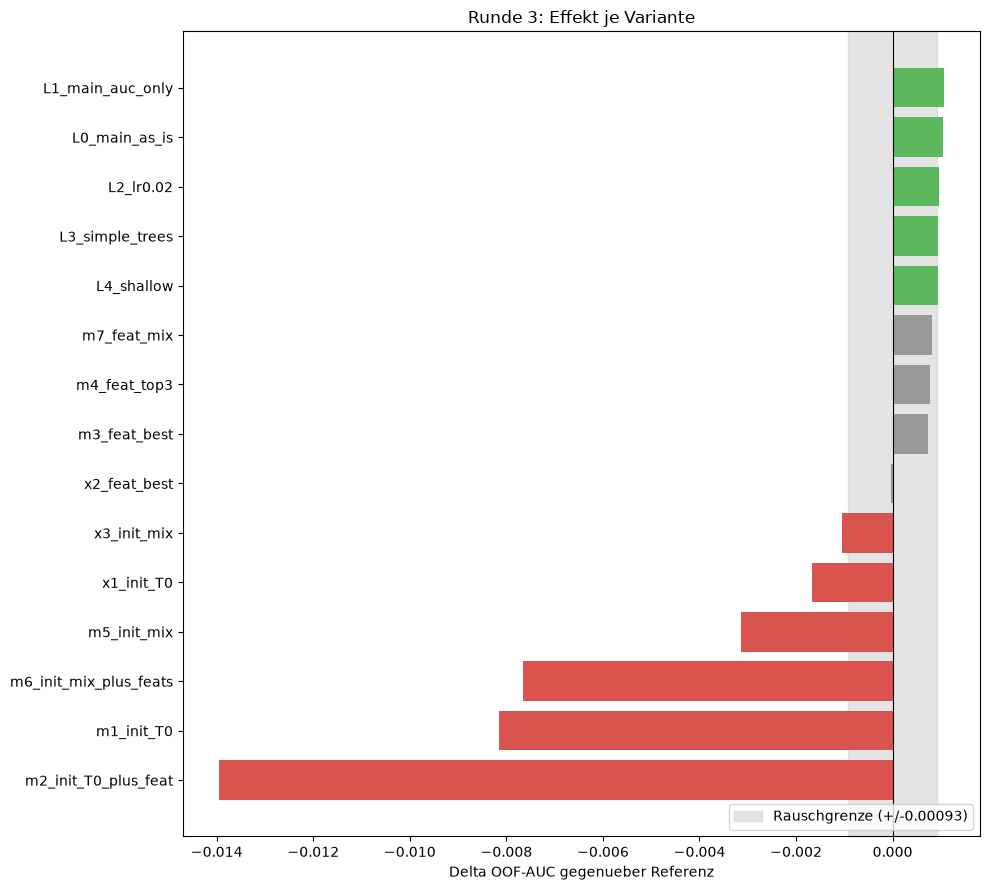

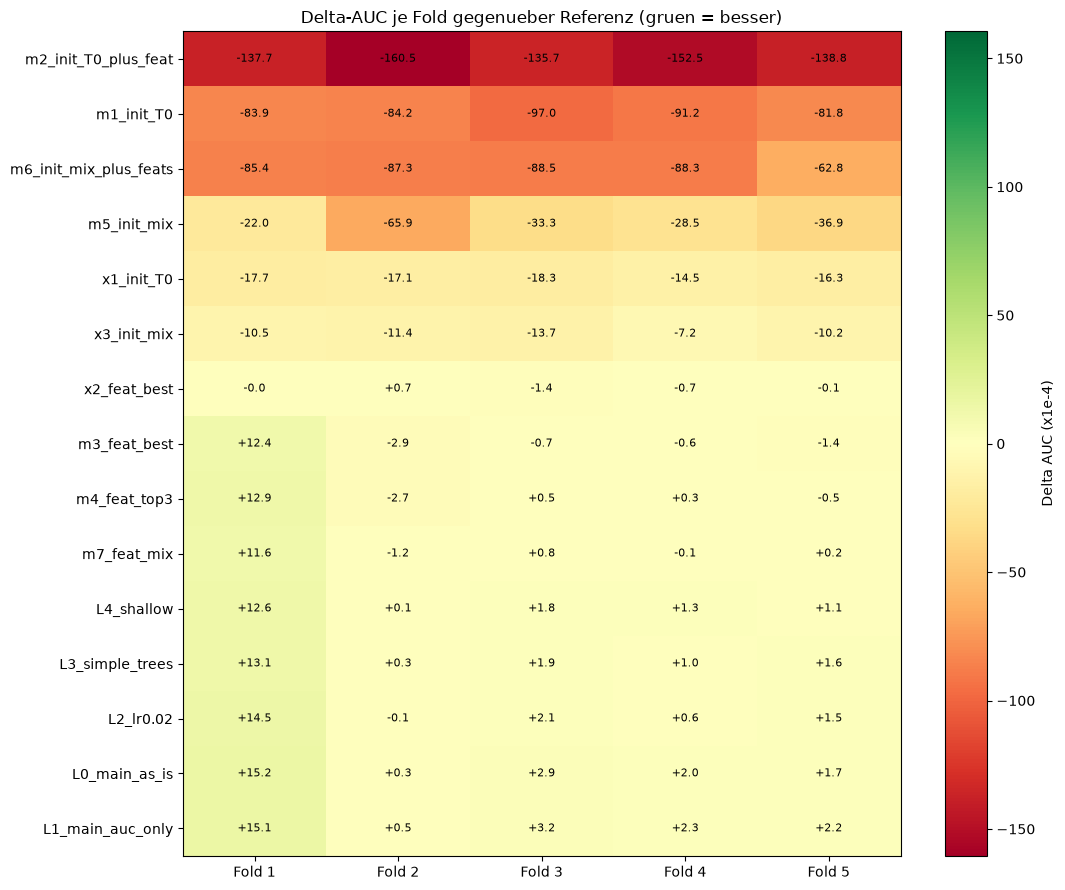

In [ ]:
t = table[table["urteil"].isin(["besser", "schlechter", "neutral"])].sort_values("delta_vs_parent")
col = t["urteil"].map({"besser": "#5cb85c", "neutral": "#999999", "schlechter": "#d9534f"})
fig, ax = plt.subplots(figsize=(10, 0.5 * len(t) + 1.5))
ax.axvspan(-THR, THR, color="lightgray", alpha=0.6, label=f"Rauschgrenze (+/-{THR:.5f})")
ax.barh(t.index, t["delta_vs_parent"], color=col)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Delta OOF-AUC gegenueber Referenz"); ax.set_title("Runde 3: Effekt je Variante")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

names = list(t.index)
M = np.array([(np.array(results[(n, ABL_SEED)]["fold_aucs"]) -
               np.array(results[(table.loc[n, "parent"], ABL_SEED)]["fold_aucs"])) * 1e4 for n in names])
v = max(abs(M).max(), 0.5)
fig, ax = plt.subplots(figsize=(1.2 * M.shape[1] + 5, 0.5 * len(names) + 1.5))
im = ax.imshow(M, cmap="RdYlGn", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([f"Fold {i+1}" for i in range(M.shape[1])])
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:+.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Delta AUC (x1e-4)")
ax.set_title("Delta-AUC je Fold gegenueber Referenz (gruen = besser)")
plt.tight_layout(); plt.show()

## Empfehlung für die Pipeline

In [ ]:
tab = build_table()
ref = results[("m0_ref", ABL_SEED)]["auc"]
print("=== 1) LGBM-Diagnose ===")
if ("L0_main_as_is", ABL_SEED) in results and ("L1_main_auc_only", ABL_SEED) in results:
    l0, l1 = results[("L0_main_as_is", ABL_SEED)], results[("L1_main_auc_only", ABL_SEED)]
    print(f"L0 (Logloss+AUC, wie models.py): {l0['auc']:.6f} (best_it~{l0['mean_best_iter']:.0f})")
    print(f"L1 (nur AUC)                   : {l1['auc']:.6f} (best_it~{l1['mean_best_iter']:.0f})")
    if l1["auc"] - l0["auc"] > THR:
        print("-> Ursache: Early Stopping auf Logloss. FIX in models.py: LGBMClassifier(..., metric='auc')")
    else:
        print("-> Early Stopping ist nicht die Ursache; Parameter aendern (siehe L2-L4).")
else:
    print("L0/L1 nicht gelaufen (RUN_SLOW = False).")
lg = [n for n in tab.index if n.startswith("L") and n[1].isdigit()]
if lg:
    bl = max(lg, key=lambda n: tab.loc[n, "auc"])
    print(f"Beste LGBM-Parametervariante: {bl}  AUC {tab.loc[bl, 'auc']:.6f}")
    print("  Parameter:", SPECS[bl]["lgbm"], "| ES:", SPECS[bl]["es"], "| metric:", SPECS[bl]["metric"])

print("\n=== 2) Teacher ===")
print(f"Bester Teacher: {BEST} (Train-AUC {TEACHERS[BEST]['auc_train']:.4f}; T0: {TEACHERS['T0_xgb_d8']['auc_train']:.4f})")
mm = [n for n in tab.index if n.startswith("m") and n[1].isdigit() and n != "m0_ref"]
if mm:
    bm = max(mm, key=lambda n: tab.loc[n, "auc"])
    d_ = tab.loc[bm, "auc"] - ref
    print(f"Beste Nutzung: {bm}  AUC {tab.loc[bm, 'auc']:.6f}  ({d_:+.6f} vs m0_ref, in {int(tab.loc[bm, 'better_folds'])}/{ABL_SPLITS} Folds besser)")
    print("  ", SPECS[bm]["desc"])
    if d_ <= THR:
        print("-> Kein Gewinn gegenueber T0 als Feature: Teacher-Setup so lassen.")
    else:
        print("-> Gewinn ueber der Rauschgrenze: Teacher-Setup in der Pipeline umstellen (sag Bescheid, dann baue ich es ein).")

if XGB_CHECK and ("x0_ref", ABL_SEED) in results:
    xr = results[("x0_ref", ABL_SEED)]["auc"]
    xs = [n for n in tab.index if n.startswith("x") and n != "x0_ref"]
    print("\n=== 3) XGB-Kontrolle ===")
    for n in xs:
        print(f"{n:16s} {tab.loc[n, 'auc']:.6f} ({tab.loc[n, 'auc'] - xr:+.6f} vs x0_ref, {int(tab.loc[n, 'better_folds'])}/{ABL_SPLITS} Folds)")

=== 1) LGBM-Diagnose ===
L0 (Logloss+AUC, wie models.py): 0.960973 (best_it~1880)
L1 (nur AUC)                   : 0.960995 (best_it~1787)
-> Early Stopping ist nicht die Ursache; Parameter aendern (siehe L2-L4).
Beste LGBM-Parametervariante: L1_main_auc_only  AUC 0.960995
  Parameter: {'n_estimators': 10000} | ES: 200 | metric: auc

=== 2) Teacher ===
Bester Teacher: cat_d6 (Train-AUC 0.9550; T0: 0.9550)
Beste Nutzung: m7_feat_mix  AUC 0.960755  (+0.000819 vs m0_ref, in 3/5 Folds besser)
   Mix Top-3 als ein Feature
-> Kein Gewinn gegenueber T0 als Feature: Teacher-Setup so lassen.

=== 3) XGB-Kontrolle ===
x1_init_T0       0.959193 (-0.001673 vs x0_ref, 0/5 Folds)
x2_feat_best     0.960836 (-0.000030 vs x0_ref, 1/5 Folds)
x3_init_mix      0.959812 (-0.001054 vs x0_ref, 0/5 Folds)


## Lesehilfe
- **`m0_ref` ≈ 0.9608** bestätigt, dass Setup und Folds wie in Runde 2 funktionieren.
- **LGBM-Diagnose:** Der Vergleich `L0` ↔ `L1` trennt Early-Stopping-Effekt von Parametereffekt. `best_iter` zeigt zusätzlich, ob `L0` zu früh stoppt.
- **Teacher-Labor:** Die Train-AUC ist die direkte Obergrenze für das, was das Hauptmodell aus dem Teacher ziehen kann. Ein Teacher, der auf Original sehr gut (≈ 0.995), auf Train aber schlechter ist, hat den größten „Gap“ – meist ein Zeichen für Überanpassung an die Eigenheiten des Originals.
- **`init_score` ↔ Feature:** Beim Startwert lernt das Hauptmodell nur noch die Abweichung vom Teacher, beim Feature muss es die Abbildung selbst finden. Welche Variante besser ist, entscheidet nur die CV – nicht die Theorie.
- **Mix-Teacher:** Ein Mittel verschiedener Modellfamilien ist oft besser als jede Einzelkomponente; das zeigt die Train-AUC der `ens_*`-Einträge sofort.
- **XGB-Kontrolle:** Nur wenn sich ein Effekt bei LGBM *und* XGB zeigt, ist er belastbar.
- **Grenzen:** 1 Seed, 5 Folds, schnelle Parameter. Effekte unter ca. 0.0001 nur übernehmen, wenn sie in fast allen Folds konsistent sind.